## Data Cleaning and Quality Assessment
## Homework 5 - Data Quality
## Hadi Seyed

### 1. Excercise
### Task 1 - Identify age oversampling and create `sampling_multiplier`

Compare the survey's age distribution with a rough 2010 U.S. adult age distribution. A multiplier above 1 means the age group appears underrepresented in the survey relative to the population baseline; below 1 means it appears overrepresented. The values are estimates because the population baseline is grouped and approximate.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pew = pd.read_csv("pew-survey.csv")
print("Shape:", pew.shape)
print("Columns:", pew.columns.tolist())
pew.head()

Shape: (2020, 187)
Columns: ['resp', 'comp', 'fproj', 'timezone', 'sfips', 'smsa', 'qcendiv', 'sstate', 'phtype', 'susr', 'qmarket', 'scregion', 'sdensity3', 'cregion', 'state', 'fips', 'density3', 'qlan', 'qs1', 'cintro', 'qs1a', 'ns1', 'cointro', 'qs2a', 'qs2b', 'ss2c', 'qs3', 'qs4', 'sex', 'q1', 'q2', 'q3', 'q4', 'q6', 'q7oe', 'q7.1', 'q7.2', 'q7.3', 'q7.4', 'q7.5', 'q7@', 'q7a', 'q8a', 'q8b', 'q8c', 'q8d', 'q8e', 'q8f', 'q8g', 'q8h', 'int1', 'int2', 'q9a', 'q9b', 'q9c', 'q9d', 'q9e', 'q9f', 'q10', 'q10a', 'q10b', 'q13', 'q14', 'q15', 'age', 'educ', 'schl', 'schl2', 'schl2@', 'rschl', 'rschl2', 'rschl2@', 'q17', 'q17@', 'q18a', 'q18b', 'q18c', 'q18d', 'q18e', 'q19', 'q20', 'q21', 'q22', 'q23a', 'q23b', 'q23c', 'l1', 'q24', 'q25', 'q25a', 'q26a', 'q26b', 'q26c', 'q26d', 'q26e', 'q26f', 'q26g', 'employ', 'employ2', 'employ2@', 'employ3', 'q31', 'q32', 'q33', 'q34', 'q35', 'q36', 'q37', 'q38', 'q39', 'q40', 'q41', 'q42', 'q43', 'q44a', 'q44b', 'q44c', 'q44d', 'q44dd', 'q44e', 'q44f', '

,resp,comp,fproj,timezone,sfips,smsa,qcendiv,sstate,phtype,susr,...,irace1_4,ilang,fdate,fdow,phoneuse,adults,psadjust,puadjust,wt1,q46x
0,2.0,Complete,4968,Eastern,36061,35620.0,2,NY,1.0,U,...,NaN,English,100114,Thursday,"Dual/few, some cell",3.0,2.0,1.0,2.0,0.0
1,4.0,Complete,4968,Central,31055,36540.0,4,NE,1.0,U,...,NaN,English,100114,Thursday,"Dual/few, some cell",2.0,2.0,1.0,2.0,1.0
2,5.0,Complete,4968,Eastern,18023,0.0,3,IN,1.0,R,...,NaN,English,100114,Thursday,"Dual/few, some cell",2.0,2.0,1.0,2.0,0.0
3,6.0,Complete,4968,Eastern,18057,26900.0,3,IN,0.0,S,...,NaN,English,100114,Thursday,"Dual/few, some cell",2.0,2.0,1.0,2.0,0.0
4,7.0,Complete,4968,Eastern,51065,16820.0,5,VA,1.0,S,...,NaN,English,100114,Thursday,"Dual/few, some cell",2.0,2.0,1.0,2.0,0.0


,survey_share,approx_population_share,population_to_sample_ratio
18–24,0.250,0.130,0.523
25–34,0.218,0.185,0.848
35–44,0.113,0.174,1.543
45–54,0.133,0.207,1.554
55–64,0.126,0.163,1.291
65+,0.161,0.141,0.880


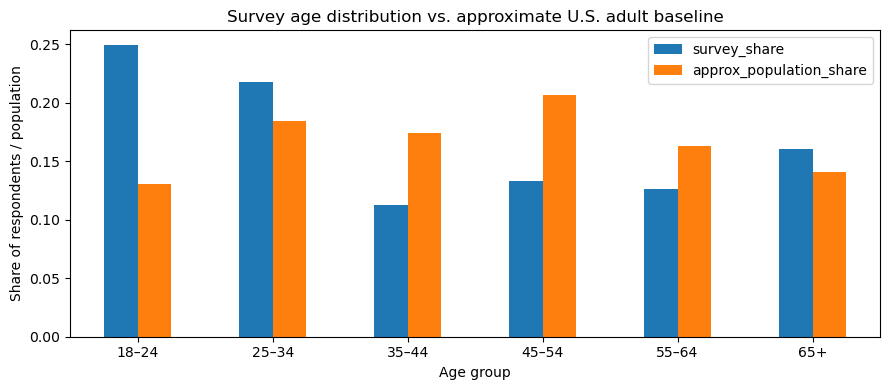

In [3]:
# Find the age column without assuming capitalization.
age_col = next((c for c in pew.columns if c.lower() == "age"), None)
if age_col is None:
    raise ValueError("Could not find an age column. Check pew.columns.")

pew[age_col] = pd.to_numeric(pew[age_col], errors="coerce")

# Approximate 2010 U.S. adult population shares by age group.
# These are baseline estimates, not exact age-by-age Census counts.
age_bins = [18, 25, 35, 45, 55, 65, 120]
age_labels = ["18–24", "25–34", "35–44", "45–54", "55–64", "65+"]
population_share = pd.Series(
    [0.12, 0.17, 0.16, 0.19, 0.15, 0.13], index=age_labels, dtype=float
)
population_share = population_share / population_share.sum()

pew["age_group"] = pd.cut(
    pew[age_col], bins=age_bins, labels=age_labels, right=False, include_lowest=True
)
sample_share = pew["age_group"].value_counts(normalize=True).reindex(age_labels).fillna(0)

comparison = pd.DataFrame({
    "survey_share": sample_share,
    "approx_population_share": population_share
})
comparison["population_to_sample_ratio"] = (
    comparison["approx_population_share"] / comparison["survey_share"].replace(0, np.nan)
)
display(comparison.round(3))

ax = comparison[["survey_share", "approx_population_share"]].plot(
    kind="bar", figsize=(9, 4), title="Survey age distribution vs. approximate U.S. adult baseline"
)
ax.set_ylabel("Share of respondents / population")
ax.set_xlabel("Age group")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [4]:
# Assign the estimated group ratio to each row.
# Normalize so the average multiplier across the sample is approximately 1.
ratio = comparison["population_to_sample_ratio"].replace([np.inf, -np.inf], np.nan)
ratio = ratio.fillna(1.0)
ratio = ratio / np.average(ratio.reindex(sample_share.index).fillna(1.0),
                          weights=sample_share.reindex(ratio.index).fillna(0.0))
age_multiplier = ratio.to_dict()
pew["sampling_multiplier"] = pew["age_group"].map(age_multiplier).astype(float)

display(pew[[age_col, "age_group", "sampling_multiplier"]].head(10))
print("Multiplier summary:")
display(pew["sampling_multiplier"].describe().to_frame())

,age,age_group,sampling_multiplier
0,28.0,25–34,0.847952
1,33.0,25–34,0.847952
2,45.0,45–54,1.554389
3,66.0,65+,0.880162
4,52.0,45–54,1.554389
5,NaN,NaN,NaN
6,60.0,55–64,1.290707
7,54.0,45–54,1.554389
8,48.0,45–54,1.554389
9,48.0,45–54,1.554389


Multiplier summary:


,sampling_multiplier
count,1987.000000
mean,1.000000
std,0.386058
min,0.522528
25%,0.847952
50%,0.880162
75%,1.290707
max,1.554389


**Answer:** The table and chart identify which age groups have more or fewer survey responses than expected from the approximate adult population baseline. The `sampling_multiplier` column applies the population-to-sample ratio to every respondent. Groups overrepresented in the sample receive multipliers below 1; underrepresented groups receive multipliers above 1. Since the baseline is approximate, the multipliers should be treated as informed estimates rather than official Pew weights.

### Task 2 - Re-encode categorical values as multiple booleans

For `q23a`, the two substantive answers describe different claims: technology makes people closer to friends/family, or it makes people more isolated. Keeping them as separate boolean features is useful for analysis. The other responses are not affirmative answers to either claim, so both flags remain false; the original field is preserved to distinguish “both,” “neither,” and refusal.

In [5]:
q23a_col = next((c for c in pew.columns if c.lower() == "q23a"), None)
if q23a_col is None:
    raise ValueError("Could not find q23a in the dataset.")

q23a = pew[q23a_col].astype("string").str.strip()
pew["technology_makes_closer"] = (
    q23a.eq("New technology makes people closer to their friends and family")
)
pew["technology_makes_isolated"] = (
    q23a.eq("New technology makes people more isolated")
)

display(pew[[q23a_col, "technology_makes_closer", "technology_makes_isolated"]]
        .drop_duplicates().sort_values(q23a_col))

,q23a,technology_makes_closer,technology_makes_isolated
19,(VOL) Both equally,False,False
34,(VOL) Don't know/Refused,False,False
85,(VOL) Neither equally,False,False
0,New technology makes people closer to their fr...,True,False
2,New technology makes people more isolated,False,True


**Answer:** Two boolean columns preserve the independent meanings of “closer” and “more isolated.” The original `q23a` remains available because “both equally,” “neither equally,” and “don’t know/refused” are distinct answers. They should not be silently treated as missing or as agreement with either statement.

### Task 3 - Check whether other demographic fields were oversampled

Inspect the distributions of likely demographic variables and compare them with external population expectations where available. The timezone comparison is only a rough diagnostic: time zones do not map perfectly to population shares because some states span zones and the survey may define geography differently.

In [6]:
candidate_cols = [
    c for c in pew.columns
    if any(term in c.lower() for term in
           ["timezone", "gender", "sex", "race", "ethnic", "education",
            "income", "marital", "region", "state", "religion", "age"])
]
for col in candidate_cols:
    print(f"\\n{col}:")
    display(pew[col].value_counts(dropna=False, normalize=True).mul(100)
            .round(1).rename("percent").to_frame())

\ntimezone:


,percent
timezone,
Eastern,48.1
Central,30.3
Pacific,14.5
Mountain,7.1


\nsstate:


,percent
sstate,
NaN,58.6
CA,3.4
TX,2.3
NY,2.3
FL,2.0
OH,1.8
PA,1.7
IL,1.6
WA,1.6


\nscregion:


,percent
scregion,
3,37.5
2,23.3
4,21.3
1,17.9


... (32 outputs left out)

\nirace1_4:


,percent
irace1_4,
NaN,100.0


\nage_group:


,percent
age_group,
18–24,24.6
25–34,21.4
65+,15.8
45–54,13.1
55–64,12.4
35–44,11.1
NaN,1.6


,survey_percent
timezone,
Eastern,48.069307
Central,30.297030
Pacific,14.504950
Mountain,7.128713


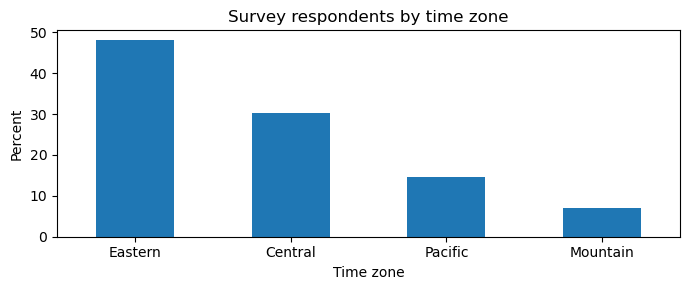

In [7]:
# Time-zone share in this sample (if the field is present).
timezone_col = next((c for c in pew.columns if c.lower() == "timezone"), None)
if timezone_col:
    tz_sample = pew[timezone_col].value_counts(normalize=True).mul(100).rename("survey_percent")
    display(tz_sample.to_frame())
    ax = tz_sample.sort_values(ascending=False).plot(
        kind="bar", figsize=(7, 3), title="Survey respondents by time zone"
    )
    ax.set_ylabel("Percent")
    ax.set_xlabel("Time zone")
    plt.xticks(rotation=0)
    plt.tight_layout()
    plt.show()
else:
    print("No timezone column found.")

**Answer:** A demographic field should be called oversampled only when its survey distribution differs materially from a credible population baseline. Age is assessed in Task 1. For other fields, use the frequency tables above and compare categories with 2010 Census or other appropriate population estimates. Time-zone differences alone are suggestive, not conclusive, because the survey's geographic coding and population definitions may not match the baseline exactly. Do not treat opinion questions such as `q1` as demographic variables.

### Task 4 - Re-encode ordinal fields

Ordinal values have a meaningful order, but the numeric codes do not imply equal distances between responses. For `q1`, “Very happy” is more positive than “Pretty happy,” which is more positive than “Not too happy.” Refusal is not part of that ranking, so it is encoded as missing in the ordinal feature while the original response is preserved.

In [8]:
q1_col = next((c for c in pew.columns if c.lower() == "q1"), None)
if q1_col is None:
    raise ValueError("Could not find q1 in the dataset.")

q1_order = {
    "Very happy": 1,
    "Pretty happy": 2,
    "Not too happy": 3
}
pew["q1_happiness_ordinal"] = pew[q1_col].map(q1_order).astype("Float64")

# Keep refusal / don't-know values as missing in the ordinal representation.
# This avoids pretending that nonresponse is a meaningful happiness level.
display(pew[[q1_col, "q1_happiness_ordinal"]].drop_duplicates().sort_values(q1_col))
print("Encoded q1 values:")
display(pew["q1_happiness_ordinal"].value_counts(dropna=False).sort_index().to_frame("count"))

,q1,q1_happiness_ordinal
56,(VOL) Don't know/Refused,<NA>
7,Not too happy,3.0
2,Pretty happy,2.0
0,Very happy,1.0


Encoded q1 values:


,count
q1_happiness_ordinal,
1.0,573
2.0,1121
3.0,296
<NA>,30


**Answer:** `q1_happiness_ordinal` uses 1 for “Very happy,” 2 for “Pretty happy,” and 3 for “Not too happy.” The direction is documented explicitly so smaller values mean greater happiness. “Don’t know/refused” becomes missing in this new feature, but the original `q1` column is retained. Other fields should be ordinally encoded only when their answer categories have a defensible order; nominal categories such as timezone or gender should not be assigned arbitrary ranks.

### 2. Extra credit - Summary of outlier-detection methods

**Statistics-based methods.** These methods model normal observations as likely under a statistical distribution and flag values in low-probability regions. They can provide interpretable scores or confidence levels, but results depend on distributional assumptions and the chosen threshold.

**Distance-based methods.** These methods measure how far a point is from other observations. A point may be an outlier if it is far from many neighbors or has too few neighbors within a distance. They are useful without assuming a specific probability distribution, but the choice of distance and neighborhood threshold matters, and scaling features is important.

**Model-based methods.** These methods learn a model of normal behavior from labeled examples or learned patterns, then flag points that the model cannot classify as normal. They can capture more complex structure, but depend on model quality and on having representative training data.

**High-dimensional data.** Outlier detection becomes harder as the number of features grows: distances can become less informative, irrelevant dimensions can hide anomalies, and the data become sparse. Feature selection, dimensionality reduction, or methods designed for high-dimensional data may help.

**Conclusion:** No single method is best for every dataset. Choose a method based on the data type, dimensionality, assumptions, and the cost of false alarms. Investigate flagged observations before deleting them; an outlier can be an error, a rare but valid case, or a meaningful signal.

**Source:** Ilyas, I. F. and Chu, X., *Data Cleaning* (ACM Books, 2019), Chapter 2, “Outlier Detection,” especially the taxonomy and sections on statistics-based, distance-based, model-based, and high-dimensional outlier detection.

### References
- Ilyas, I. F., & Chu, X. (2019). *Data Cleaning*. ACM Books, Chapter 2: “Outlier Detection.” https://doi.org/10.1145/3310205.3310208
- Pew Research Center, “Millennials: A Portrait of Generation Next.” https://www.pewsocialtrends.org/2010/02/24/millennials-confident-connected-open-to-change/